# IPL form forecasting: completed research results

**Kashyap Karthik · 12 October 2026**

This notebook reads the saved outputs of `python run_all.py`. It distinguishes the within-season shrinkage experiment, sequential cross-season adaptation, and forecasts frozen before the next season. Read `docs/RESEARCH_REPORT.md` for the complete methods and limitations.

The primary finding is modest predictive improvement from recent weighting. The context-adjusted incremental effect is uncertain; this is not proof of permanent player improvement.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
R = ROOT / 'results'
selection = json.loads((R / 'selection.json').read_text())
selection

{'sequential': {'winner': 'ew_days_365',
  'family_winners': {'rolling_': 'rolling_300',
   'ew_balls_': 'ew_balls_300',
   'ew_days_': 'ew_days_365'},
  'display_models': ['population',
   'raw_expanding',
   'current',
   'expanding',
   'rolling_300',
   'ew_balls_300',
   'ew_days_365'],
  'selection_season': 2024,
  'selection_log_loss': 0.5121376585588722},
 'preseason': {'winner': 'rolling_300',
  'family_winners': {'rolling_': 'rolling_300',
   'ew_balls_': 'ew_balls_300',
   'ew_days_': 'ew_days_730'},
  'display_models': ['population',
   'raw_expanding',
   'current',
   'expanding',
   'rolling_300',
   'ew_balls_300',
   'ew_days_730'],
  'selection_season': 2024,
  'selection_log_loss': 0.5147897791385588},
 'protocol_sha256': '6f978a5e68a38d09fcc673f9a1d5759f0171972fbbbdcaf787886420737abf2f'}

## 1. Check what was selected, and when

2024 chooses 365-day exponential decay for forecasts updated before match dates and a 300-ball window for preseason forecasts. 2025–2026 evaluate those fixed choices. Selecting a different method because it wins on the test set would invalidate that separation.

In [2]:
pd.read_csv(R / 'sequential_validation_grid.csv')[['model','log_loss','brier']]

,model,log_loss,brier
0,ew_days_365,0.512138,0.165180
1,rolling_300,0.512204,0.165201
2,ew_days_730,0.512307,0.165224
3,ew_days_180,0.512382,0.165256
4,ew_balls_300,0.512386,0.165252
5,rolling_600,0.512432,0.165247
6,ew_balls_120,0.512533,0.165317
7,ew_balls_600,0.512684,0.165333
8,rolling_1200,0.512949,0.165399
9,ew_balls_1200,0.512997,0.165423


## 2. Early-season records predict later-season boundaries

The ≥11-opportunity subset avoids relying on very tiny samples for the transformed diagnostic. The more inclusive all-player results are also saved. Beta-binomial shrinkage outperforms raw rates, while its advantage over the pooled probability is uncertain.

In [3]:
brown = pd.read_csv(R / 'brown_metrics.csv')
brown.query("period == 'test' and subset == 'min11_both_halves'")[['model','N','log_loss','brier','noise_adjusted_arcsine_mse']]

,model,N,log_loss,brier,noise_adjusted_arcsine_mse
15,beta_binomial,12270,0.541251,0.177772,0.002349
16,population,12270,0.541535,0.178002,0.002382
17,raw,12270,0.548466,0.179630,0.007329


In [4]:
pd.read_csv(R / 'brown_uncertainty.csv')

,model,reference,observations,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high
0,beta_binomial,raw,915,54,-0.052859,-0.078565,-0.029676,-0.002748,-0.003640,-0.001843
1,beta_binomial,population,915,54,-0.000388,-0.002326,0.001445,-0.000246,-0.000939,0.000381


## 3. How much history should the forecast remember?

Every forecast below uses only outcomes on earlier dates. Annual priors use the preceding three seasons. Compare both opportunity-weighted and equal-player scores: the research answer depends on the intended objective.

In [5]:
pd.read_csv(R / 'sequential_metrics.csv').query("period == 'test'")

,model,N,players,log_loss,brier,player_macro_log_loss,player_macro_brier,period
14,current,33171,222,0.525183,0.170898,0.447559,0.137584,test
15,ew_balls_300,33171,222,0.523988,0.170507,0.443615,0.136470,test
16,ew_days_365,33171,222,0.523852,0.170457,0.446350,0.137217,test
17,expanding,33171,222,0.525423,0.170946,0.443832,0.136550,test
18,population,33171,222,0.527694,0.171799,0.451486,0.138851,test
19,raw_expanding,33171,222,0.540324,0.171362,0.497255,0.135572,test
20,rolling_300,33171,222,0.524090,0.170531,0.443684,0.136500,test


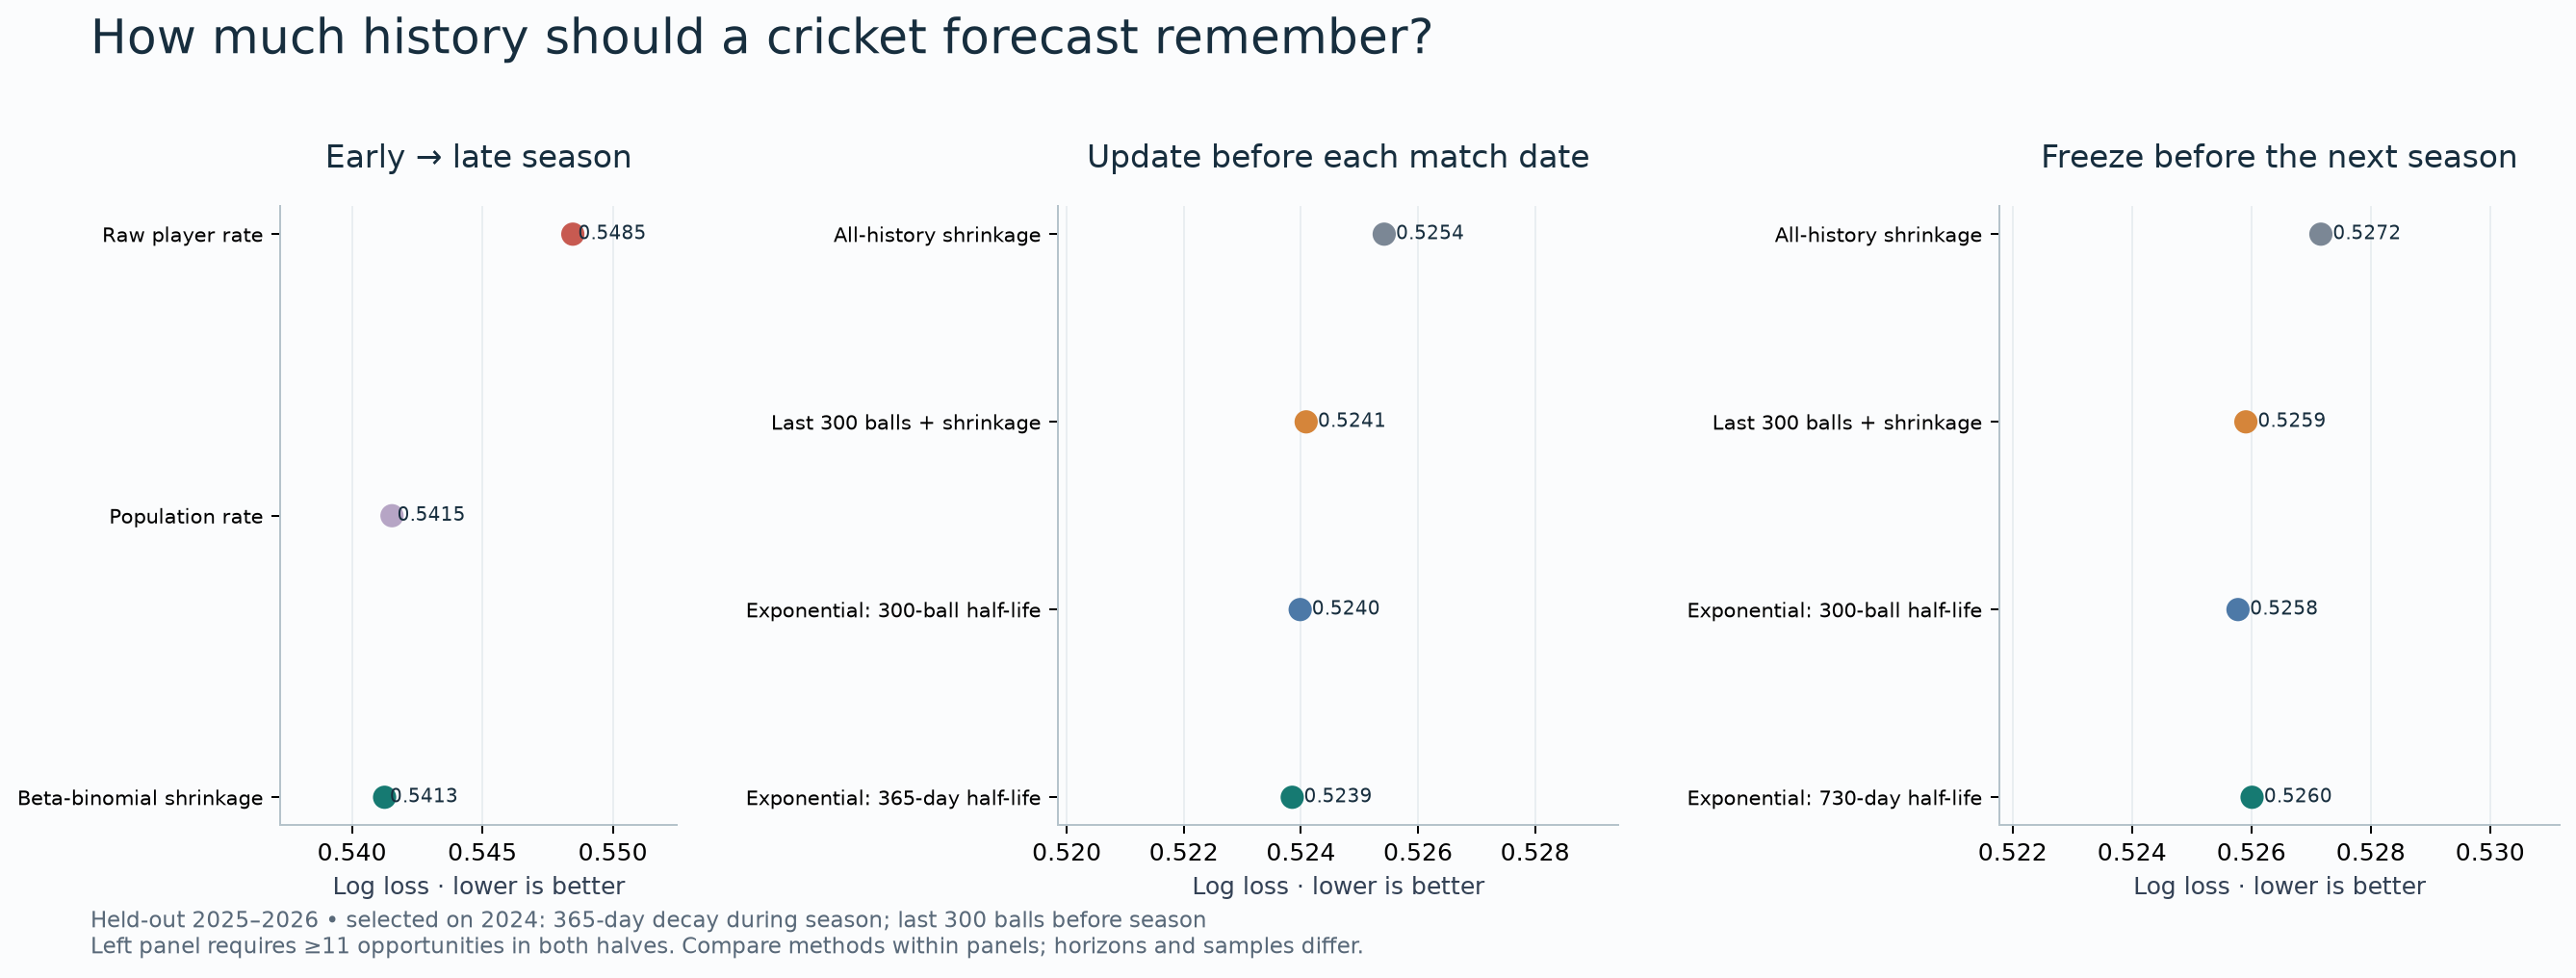

In [6]:
display(Image(filename=str(ROOT / 'figures/model_comparison.png')))

In [7]:
pd.read_csv(R / 'sequential_uncertainty.csv')

,model,reference,observations,date_blocks,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high
0,population,expanding,2252,124,0.002272,0.001069,0.003463,0.000853,0.000440,0.001268
1,raw_expanding,expanding,2252,124,0.014902,0.005393,0.027420,0.000417,0.000106,0.000768
2,current,expanding,2252,124,-0.000239,-0.001241,0.000776,-0.000048,-0.000377,0.000284
3,rolling_300,expanding,2252,124,-0.001333,-0.002166,-0.000553,-0.000414,-0.000686,-0.000159
4,ew_balls_300,expanding,2252,124,-0.001435,-0.002015,-0.000913,-0.000439,-0.000623,-0.000274
5,ew_days_365,expanding,2252,124,-0.001571,-0.002258,-0.000929,-0.000489,-0.000705,-0.000288


## 4. The off-season is a separate prediction problem

Preseason probabilities remain fixed throughout the target season. This is stricter than updating after every match. The 300-ball rolling model remains the selected forecast even though another candidate scores slightly better after the test outcomes are revealed.

In [8]:
pd.read_csv(R / 'preseason_metrics.csv').query("period == 'test'")

,model,N,players,log_loss,brier,player_macro_log_loss,player_macro_brier,period
14,current,33171,222,0.529228,0.172279,0.449690,0.138286,test
15,ew_balls_300,33171,222,0.525776,0.171102,0.444899,0.136883,test
16,ew_days_730,33171,222,0.526011,0.171177,0.447028,0.137464,test
17,expanding,33171,222,0.527164,0.171523,0.445059,0.136944,test
18,population,33171,222,0.527694,0.171799,0.451486,0.138851,test
19,raw_expanding,33171,222,0.557174,0.172105,0.505161,0.137047,test
20,rolling_300,33171,222,0.525908,0.171131,0.445053,0.136938,test


## 5. Context and uncertainty change the interpretation

The contextual comparison controls for venue group, opposition team, nominal phase, innings, observed batting-entry order, pre-delivery state and a season trend. Both contextual models use a richer information set than the main pre-innings forecasts. Their *difference* tests the extra recency signal. Its bootstrap interval includes zero.

In [9]:
pd.read_csv(R / 'context_uncertainty.csv')

,model,reference,log_loss_difference,log_loss_low,log_loss_high,brier_difference,brier_low,brier_high
0,context_plus_recent,context_expanding,-0.000047,-0.000203,0.000102,-0.000013,-0.000069,0.000043


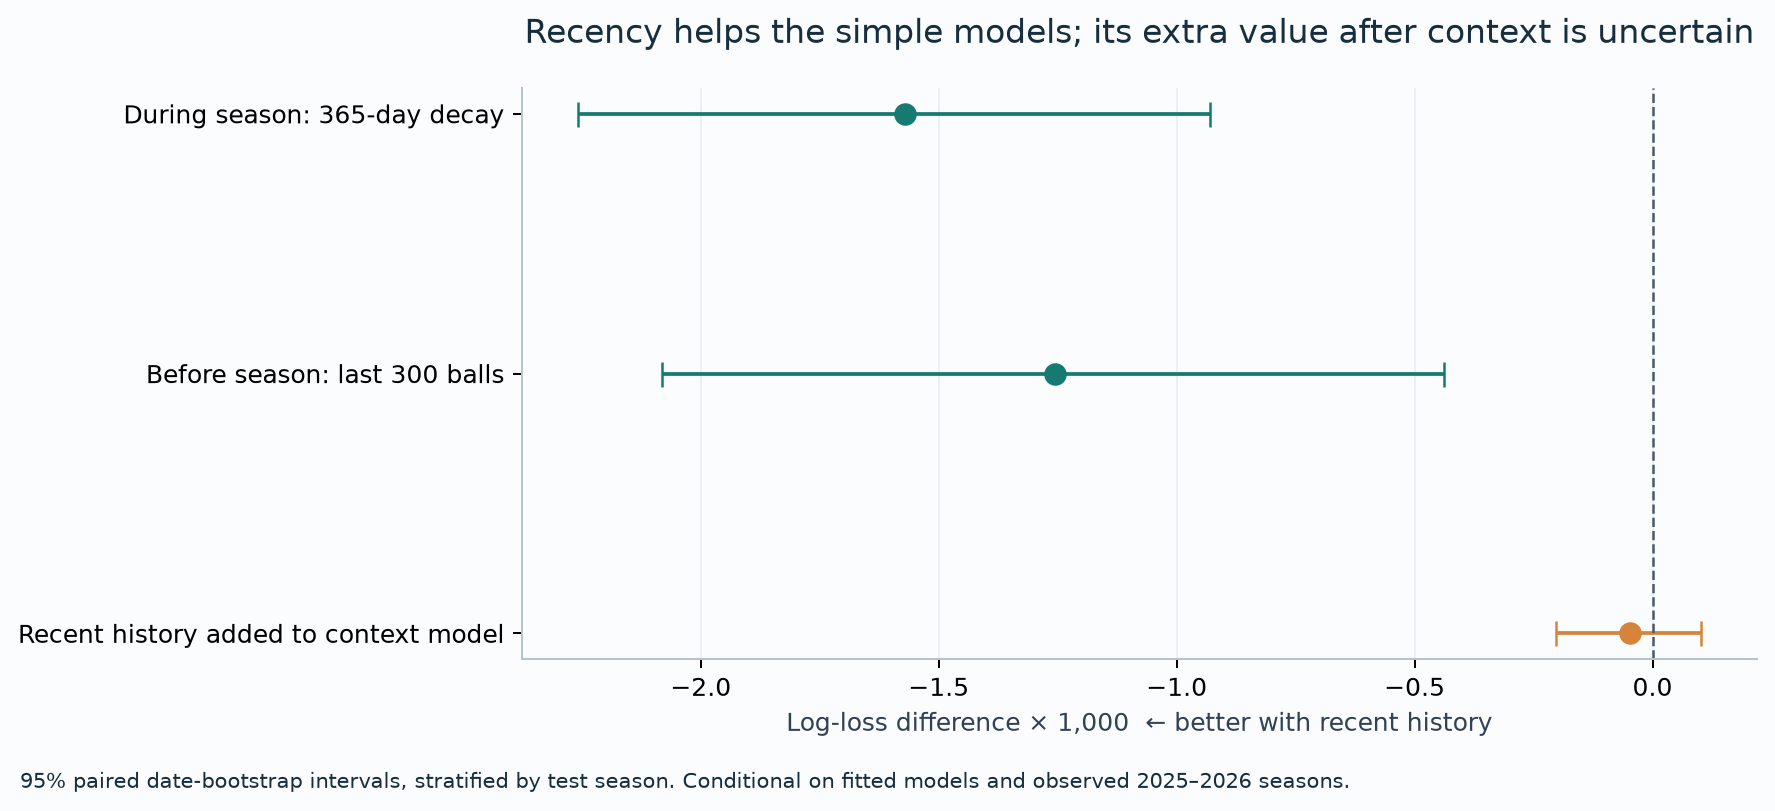

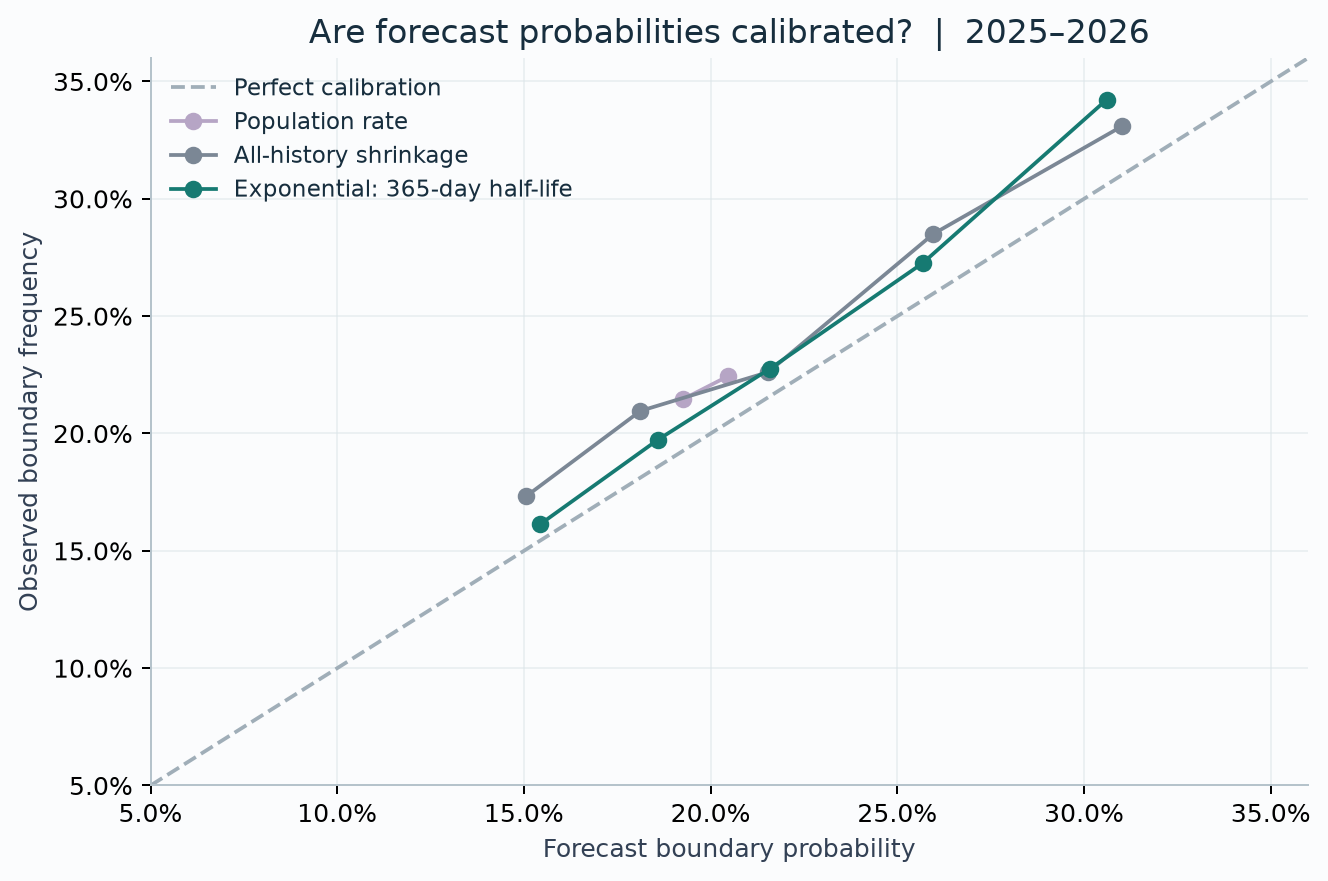

In [10]:
display(Image(filename=str(ROOT / 'figures/uncertainty.png')))
display(Image(filename=str(ROOT / 'figures/calibration.png')))

In [11]:
pd.read_csv(R / 'subgroups_phase.csv')

,group,N,boundary_rate,log_loss_difference,brier_difference
0,death,7211,0.238524,-0.002069,-0.000641
1,middle,15456,0.184330,0.000270,0.000063
2,powerplay,10504,0.258568,-0.003938,-0.001196


## 6. Dated 2027 watchlists

These predict boundary rates, not overall cricketing quality or squad selection. Eligibility requires ≥120 opportunities in 2026 and ≥300 earlier. Baseline is the shrunk pre-2026 historical rate. Intervals describe conditional block-resampling stability, not the full range of possible realised 2027 performance. Candidate labels can overlap.

A player-specific change cannot be separated completely from league conditions or changing role. Lists are a transparent forecasting application, not declarations of proven improvement.

In [12]:
columns=['player','pre_2026_N','latest_N','baseline','latest_rate','last_120_rate','forecast','forecast_low','forecast_high','change_from_baseline']
display(pd.read_csv(R / 'watchlist_improvers.csv')[columns].head(10))
display(pd.read_csv(R / 'watchlist_rebounds.csv')[columns].head(10))

,player,pre_2026_N,latest_N,baseline,latest_rate,last_120_rate,forecast,forecast_low,forecast_high,change_from_baseline
0,D Padikkal,1425,275,0.173841,0.265455,0.225000,0.249094,0.212807,0.285447,0.075253
1,SV Samson,3368,285,0.177962,0.266667,0.258333,0.251770,0.209229,0.285991,0.073808
2,KL Rahul,3827,339,0.172674,0.256637,0.200000,0.246418,0.186132,0.297476,0.073745
3,Abhishek Sharma,1108,275,0.243545,0.338182,0.333333,0.315990,0.270263,0.356714,0.072444
4,V Kohli,6501,406,0.163452,0.241379,0.241667,0.233039,0.205429,0.257755,0.069588
5,Ishan Kishan,2169,330,0.194106,0.278788,0.266667,0.262473,0.223101,0.310358,0.068367
6,SS Iyer,2790,293,0.167477,0.235495,0.241667,0.233039,0.186166,0.265644,0.065562
7,Shubman Gill,2774,449,0.176811,0.238307,0.291667,0.241067,0.201878,0.276376,0.064256
8,R Parag,1100,195,0.181017,0.230769,0.283333,0.238391,0.203689,0.266467,0.057374
9,N Rana,2079,149,0.192012,0.248322,0.266667,0.246418,0.191386,0.291909,0.054407


,player,pre_2026_N,latest_N,baseline,latest_rate,last_120_rate,forecast,forecast_low,forecast_high,change_from_baseline
0,PD Salt,595,120,0.284675,0.225000,0.225000,0.251770,0.219870,0.284798,-0.032905
1,SA Yadav,2888,183,0.213767,0.207650,0.208333,0.216984,0.191583,0.247877,0.003218
2,H Klaasen,863,390,0.214693,0.202564,0.225000,0.214309,0.167375,0.267457,-0.000385
3,RR Pant,2397,226,0.202869,0.181416,0.183333,0.208957,0.168867,0.252831,0.006088
4,N Pooran,1353,182,0.236123,0.164835,0.208333,0.200929,0.162382,0.238464,-0.035193
5,HH Pandya,1861,149,0.190397,0.187919,0.150000,0.200929,0.155415,0.251224,0.010533
6,C Green,457,220,0.202067,0.177273,0.150000,0.190226,0.155876,0.221855,-0.011841
7,RD Gaikwad,1811,272,0.180119,0.147059,0.141667,0.160792,0.131320,0.186561,-0.019326
8,T Stubbs,430,216,0.201009,0.125000,0.125000,0.150089,0.122759,0.181722,-0.050920


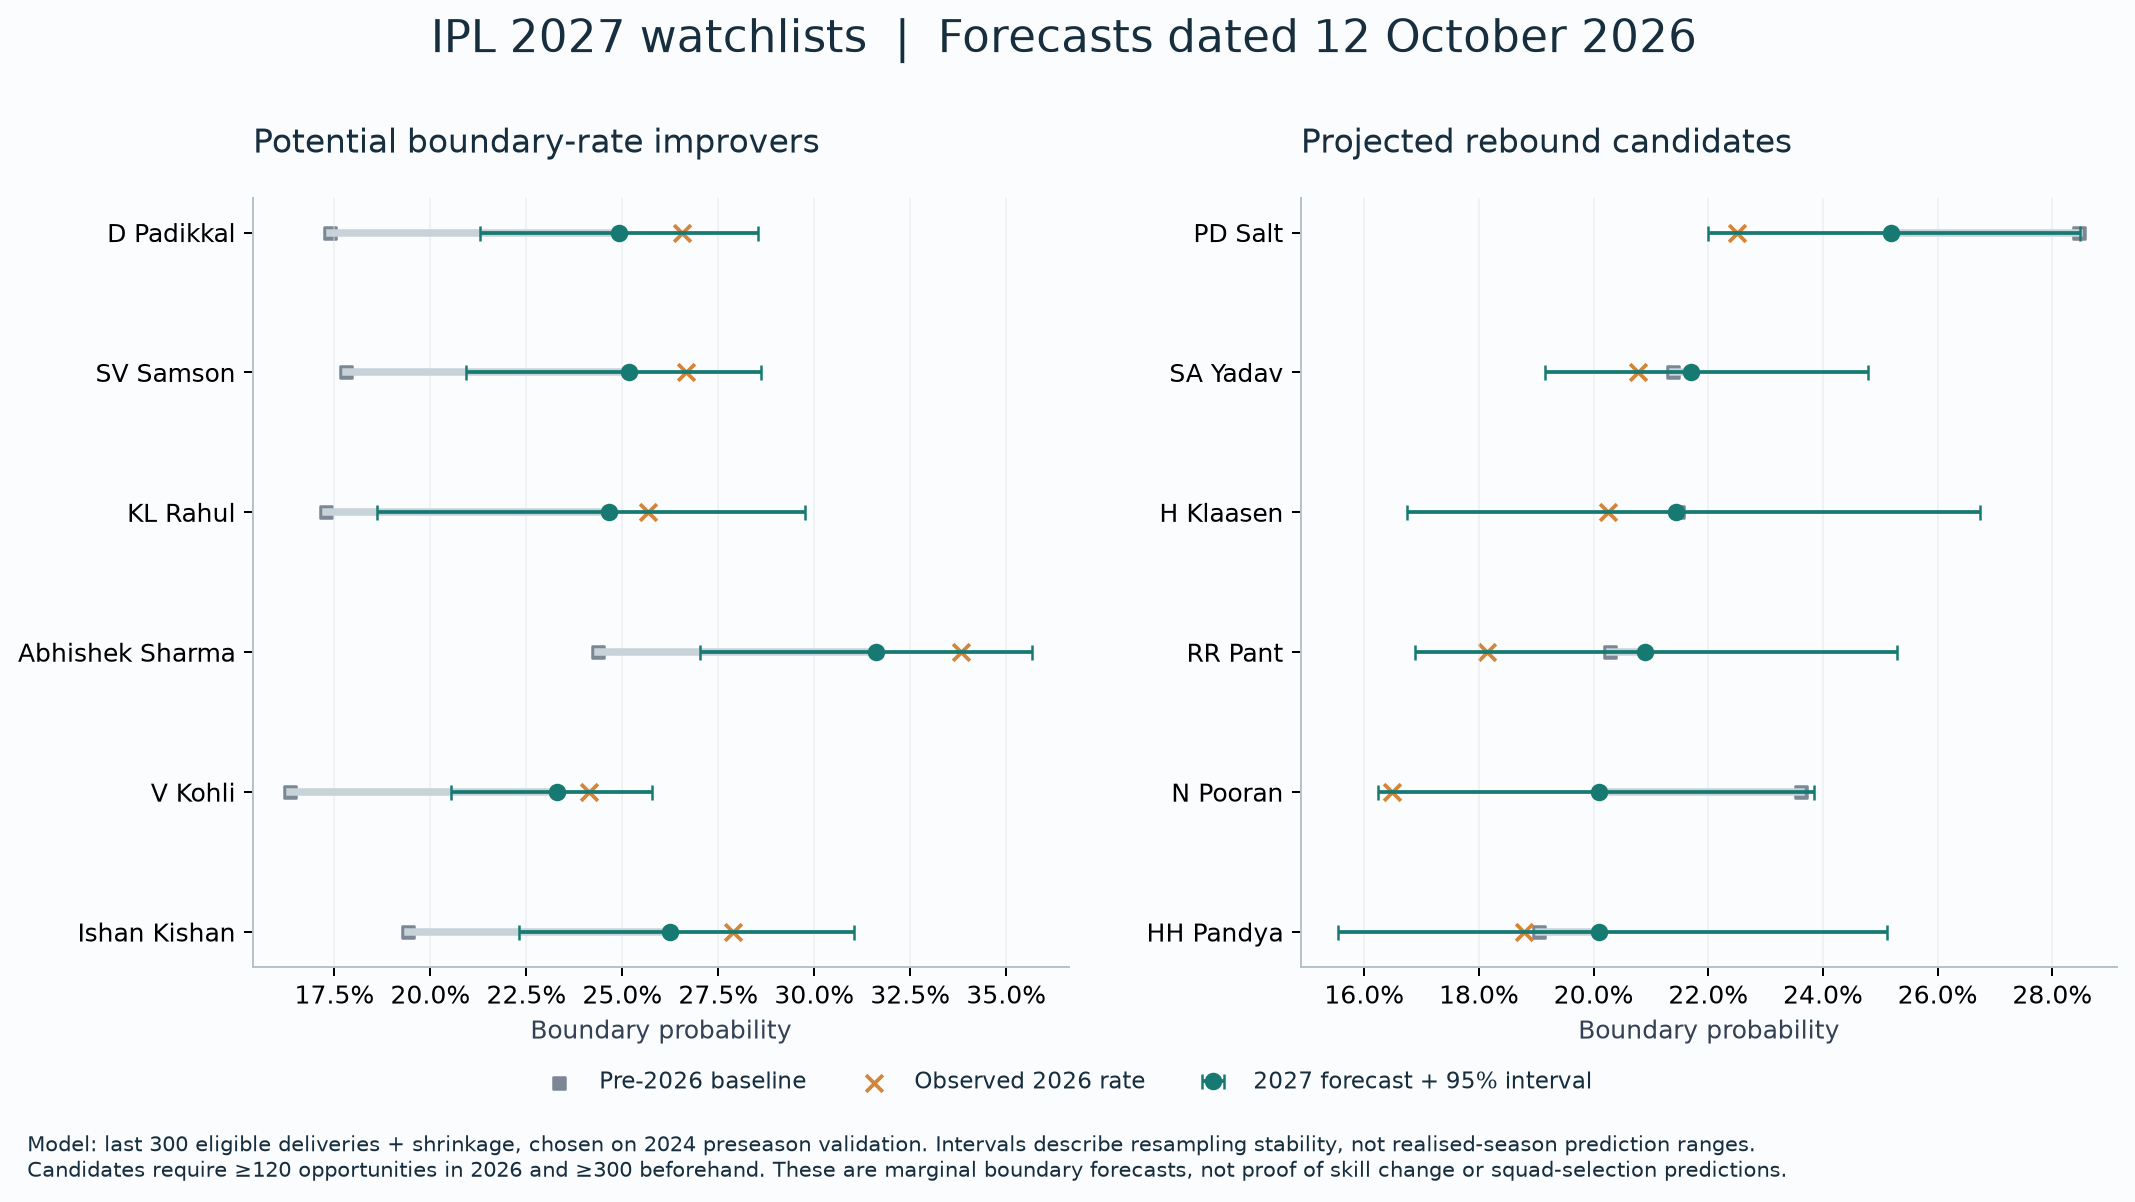

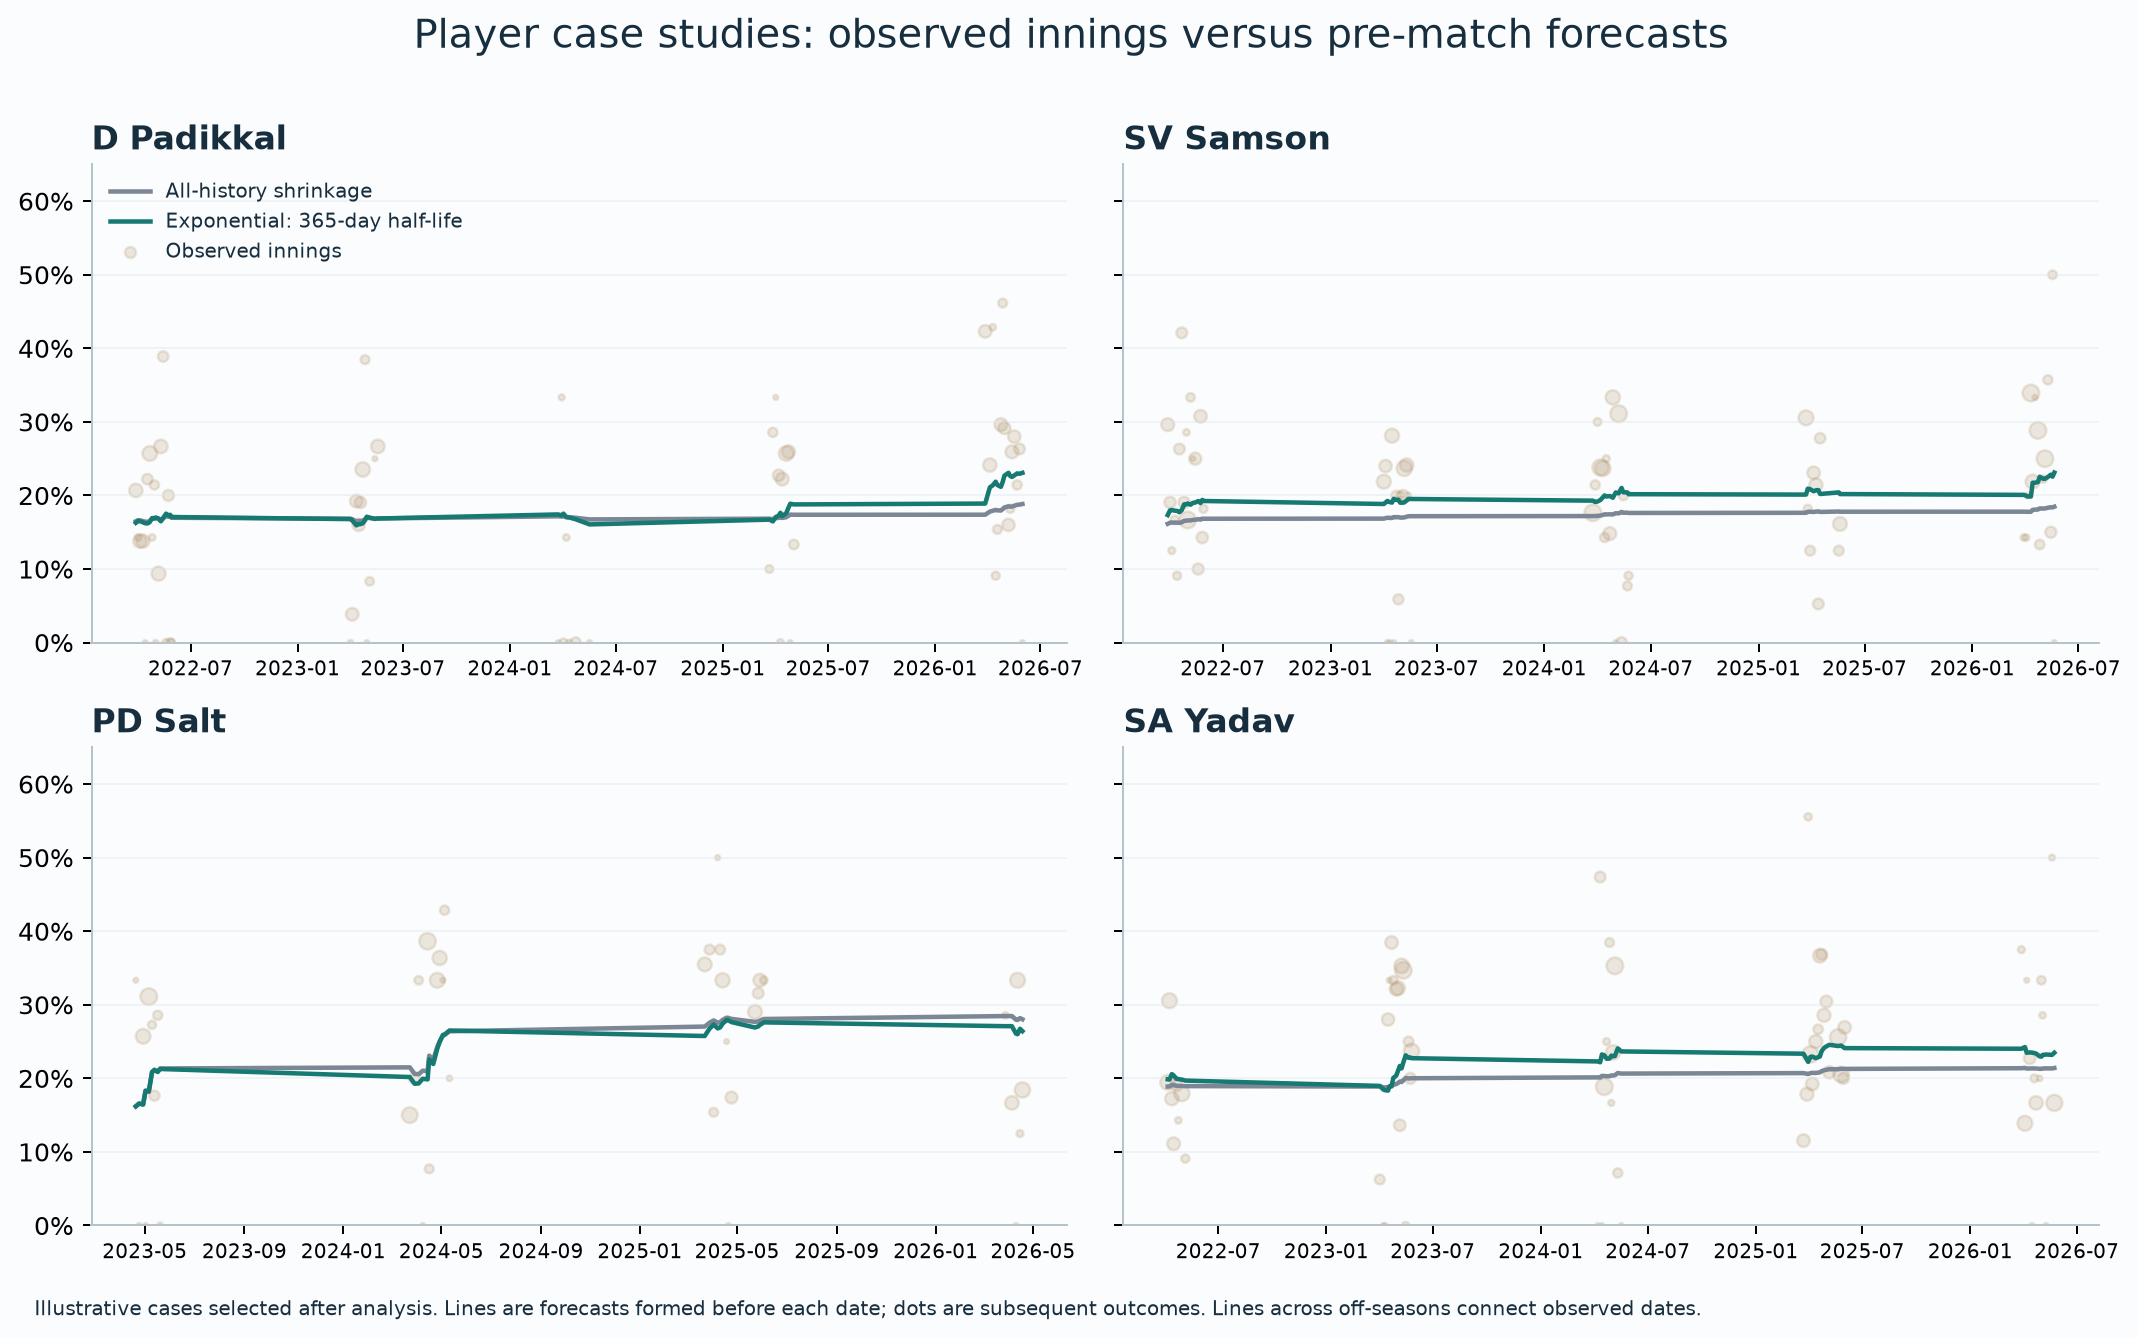

In [13]:
display(Image(filename=str(ROOT / 'figures/watchlists_2027.png')))
display(Image(filename=str(ROOT / 'figures/player_trajectories.png')))

## 7. What the research supports

- Shrinkage protects against overconfident estimates from small samples.
- Recent weighting gives modest gains in the chosen held-out, opportunity-weighted forecasting task.
- Benefits vary with horizon, scoring weights and match context.
- The current study does not identify permanent or causal skill changes.
- The 2027 forecasts are prospective and must remain dated when their eventual outcomes are evaluated.

Sources: [Cricsheet](https://cricsheet.org/), [Brown (2008)](https://www.stat.berkeley.edu/users/aldous/157/Papers/brown_batting.pdf). Data license and transformation attribution are in `DATA_LICENSE.md`.